In [36]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading wordnet: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading omw-1.4: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


In [20]:
# LOAD DATASETS
df1 = pd.read_csv("WELFake_Dataset.csv")
df2 = pd.read_csv("FakeNewsNet.csv")

print("WELFake Shape:", df1.shape)
print("FakeNewsNet Shape:", df2.shape)

WELFake Shape: (72134, 4)
FakeNewsNet Shape: (23196, 5)


In [21]:
# BASIC INFO
print(df1.info())
print(df2.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23196 entries, 0 to 23195
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   title          23196 non-null  object
 1   news_url       22866 non-null  object
 2   source_domain  22866 non-null  object
 3   tweet_num      23196 non-null  int64 
 4   real           23196 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 906.2+ KB
None


In [22]:
# MISSING VALUES
print(df1.isnull().sum())
print(df2.isnull().sum())

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64
title              0
news_url         330
source_domain    330
tweet_num          0
real               0
dtype: int64


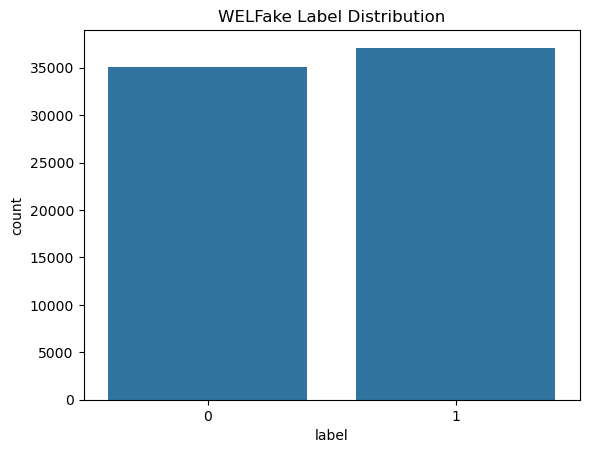

In [23]:
# LABEL DISTRIBUTION
sns.countplot(x='label', data=df1)
plt.title("WELFake Label Distribution")
plt.show()

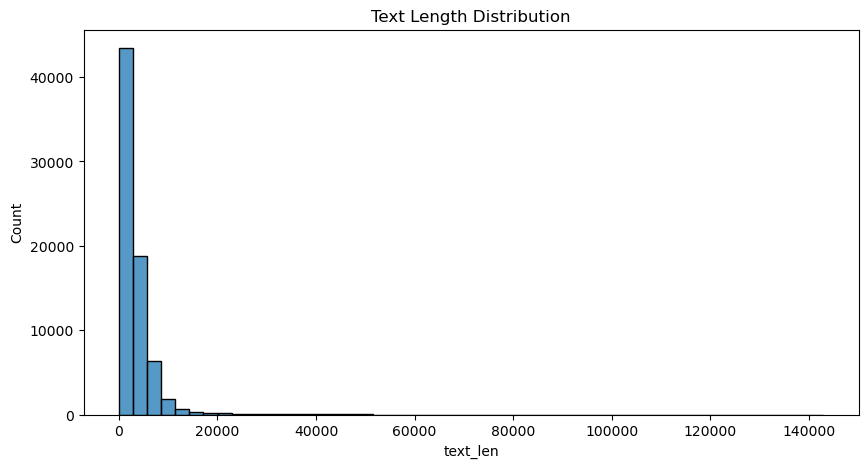

In [25]:
# TEXT LENGTH VISUALIZATION
df1["text_len"] = df1["text"].fillna("").apply(len)

plt.figure(figsize=(10,5))
sns.histplot(df1["text_len"], bins=50)
plt.title("Text Length Distribution")
plt.show()

In [26]:
# STANDARDIZE WELFAKE
df1["title"] = df1["title"].fillna("")
df1["text"] = df1["text"].fillna("")

df1["news"] = df1["title"] + " " + df1["text"]

df1 = df1[["news", "label"]]

In [27]:
# STANDARDIZE FAKENEWSNET
df2["title"] = df2["title"].fillna("")

df2["news"] = df2["title"]
df2["label"] = df2["real"]

df2 = df2[["news", "label"]]

In [28]:
# MERGE DATASETS
df = pd.concat([df1, df2], ignore_index=True)

print("Merged Shape:", df.shape)

Merged Shape: (95330, 2)


In [29]:
# NLP CLEANING FUNCTION
def clean_text(text):
    # Lowercasing
    text = str(text).lower()

    # remove urls
    text = re.sub(r"http\S+|www\S+", " ", text)

    # remove html
    text = re.sub(r"<.*?>", " ", text)

    # remove punctuation / symbols
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # tokenization
    words = text.split()

    # stopword removal
    words = [word for word in words if word not in stop_words]

    # lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

In [30]:
# APPLY PREPROCESSING
df["news"] = df["news"].apply(clean_text)

In [31]:
# rEMOVE NOISE
df = df[df["news"] != ""]

df = df.drop_duplicates(subset=["news"])

df["label"] = pd.to_numeric(df["label"], errors="coerce")

df = df.dropna()

df["label"] = df["label"].astype(int)

df = df[df["label"].isin([0,1])]

print(df["label"].value_counts())
print("Final Shape:", df.shape)

label
1    45198
0    39752
Name: count, dtype: int64
Final Shape: (84950, 2)


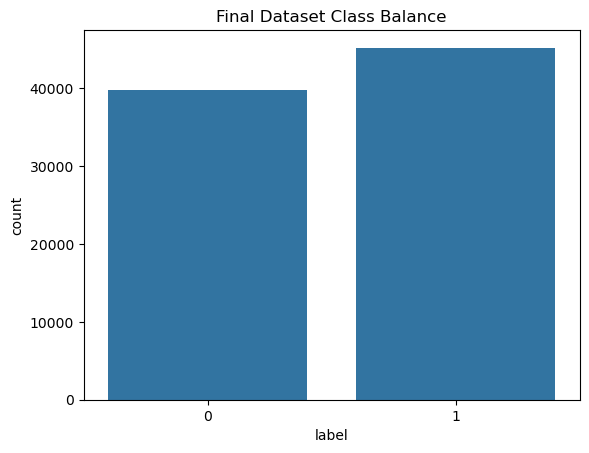

In [32]:
# FINAL CLASS DISTRIBUTION
sns.countplot(x='label', data=df)
plt.title("Final Dataset Class Balance")
plt.show()

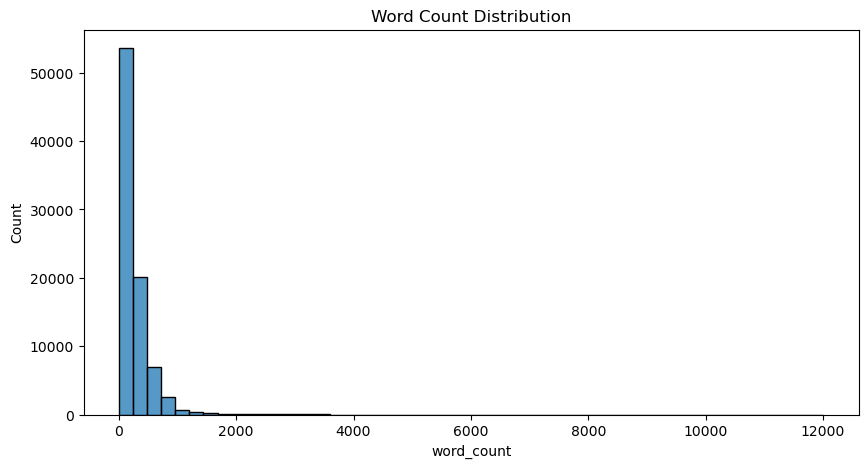

In [33]:
# WORD COUNT DISTRIBUTION
df["word_count"] = df["news"].apply(lambda x: len(x.split()))

plt.figure(figsize=(10,5))
sns.histplot(df["word_count"], bins=50)
plt.title("Word Count Distribution")
plt.show()

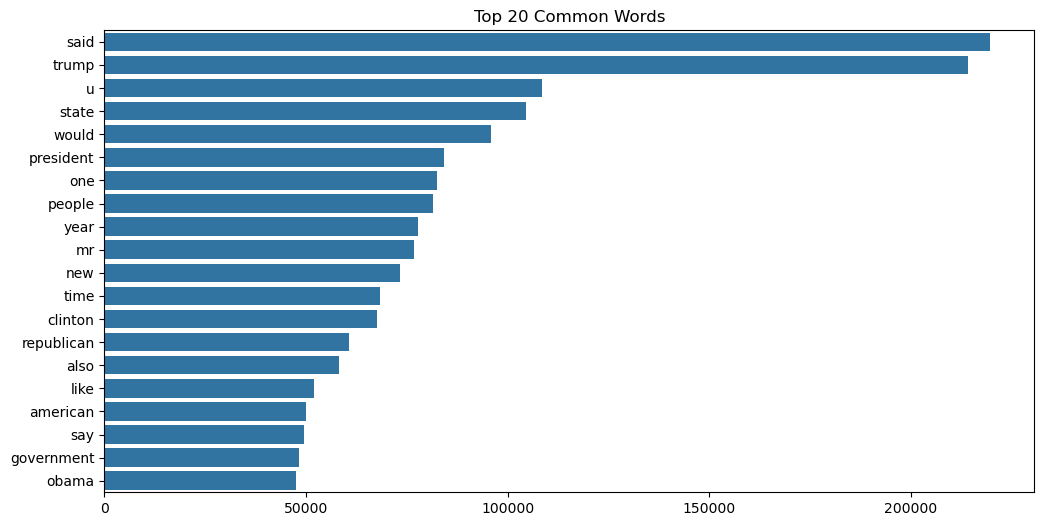

In [34]:
# TOP 20 COMMON WORDS
all_words = " ".join(df["news"]).split()

common_words = Counter(all_words).most_common(20)

words = [i[0] for i in common_words]
counts = [i[1] for i in common_words]

plt.figure(figsize=(12,6))
sns.barplot(x=counts, y=words)
plt.title("Top 20 Common Words")
plt.show()

In [35]:
# Final Dataset
df = df[["news", "label"]]

df.to_csv("final_cleaned_dataset.csv", index=False)

print("Saved Successfully")

Saved Successfully
